# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("pheatmap")
library(pheatmap)


## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}


[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#MERGE
all_data_0<-merge(demo_sdoh, PRS, on="person_id", how="inner")

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)


Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
#MERGE
merged_data<-merge(all_data_0, case_control, on="person_id", how="left")
colnames(merged_data)

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

[1] "person_id"                         "date_of_birth"                    
 [3] "AIAN"                              "Asian"                            
 [5] "Black"                             "Mid"                              
 [7] "Multiple"                          "PI"                               
 [9] "White"                             "His"                              
[11] "race_unknown"                      "SexGender"                        
[13] "age_today"                         "ancestry_pred"                    
[15] "PC_1"                              "PC_2"                             
[17] "PC_3"                              "PC_4"                             
[19] "PC_5"                              "PC_6"                             
[21] "PC_7"                              "PC_8"                             
[23] "PC_9"                              "PC_10"                            
[25] "PC_11"                             "PC_12"                            
[27] "PC_13"                             "PC_14"                            
[29] "PC_15"                             "PC_16"                            
[31] "number_living"                     "where_born"                       
[33] "military"                          "healthcare"                       
[35] "disabled"                          "sexual_orientation"               
[37] "LGBTQIA"                           "basics_survey_datetime"           
[39] "income_grouped"                    "min_date"                         
[41] "max_date"                          "ehr_length"                       
[43] "relative_health"                   "record_depth"                     
[45] "visit_frequency"                   "age"                              
[47] "record_depth_winsorized"           "visit_frequency_winsorized"       
[49] "age2"                              "income"                           
[51] "education"                         "per_poverty_threshold"            
[53] "individual_poverty"                "american_community_survey_year"   
[55] "fraction_assisted_income"          "fraction_no_high_school_education"
[57] "lower_median_income"               "fraction_no_health_insurance"     
[59] "fraction_poverty"                  "fraction_vacant_housing"          
[61] "deprivation_index"                 "Asthma_adjusted_score"            
[63] "Afib_adjusted_score"               "BreastC_adjusted_score"           
[65] "CKD_adjusted_score"                "CHD_adjusted_score"               
[67] "ProstateC_adjusted_score"          "t1d_adjusted_score"               
[69] "t2d_adjusted_score"                "Asthma"                           
[71] "Afib"                              "BreastC"                          
[73] "CKD"                               "CHD"                              
[75] "HyperC"                            "ProstateC"                        
[77] "t2d"                               "t1d"

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

sdoh_var <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

social_name_mapping <- c(
  "individual_poverty" = " Individual \nPoverty",
  "education" = "Individual\nEducation",
  "fraction_assisted_income" = "Assisted\nIncome (%)",
  "fraction_no_high_school_education" = "High School\nEducation (%)",
  "lower_median_income" = " Median Income ",
  "fraction_no_health_insurance" = "Health\nInsurance (%)",
  "fraction_poverty" = "Poverty (%)", 
  "fraction_vacant_housing" = "Vacant\nHousing (%)",
  "deprivation_index" = "Deprivation\nIndex"
)

social_name_mapping_distributions <- c(
"individual_poverty" = "Individual Poverty",
  "education" = "Lower Individual Education", 
  "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "No High School Education (%)",
  "lower_median_income" = "Lower Area Median Income",
  "fraction_no_health_insurance" = "No Health Insurance (%)",
  "fraction_poverty" = "Poverty (%)",
  "fraction_vacant_housing" = "Vacant Housing (%)",
  "deprivation_index" = "Area Deprivation Index"
)

disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Afib",
    "BreastC" = "Breast\nCancer",
    "CKD" = "CKD", 
    "CHD" = "CHD",
    "ProstateC" = "Prostate\nCancer", 
  "t2d" = "T2D",
  "t1d" = "T1D"
)

disease_order <- c("Breast\nCancer", "Prostate\nCancer", "Afib", 
                   "T2D", "CKD", "CHD",
                  "Asthma", "T1D")

sdoh_order <- c('Individual\nEducation', ' Individual \nPoverty','Assisted\nIncome (%)',
           'High School\nEducation (%)', ' Median Income ',
           'Health\nInsurance (%)', 'Poverty (%)', 'Vacant\nHousing (%)', 'Deprivation\nIndex')


## -----------------------------
## Bonferroni correction
## -----------------------------
n_disease <- length(diseases)
n_sdoh    <- length(sdoh_var)
alpha_bonf <- 0.05 / (n_disease * n_sdoh + 8)
n_disease * n_sdoh + 8

alpha_bonf 

[1] 80

[1] 0.000625

## Plot distributions

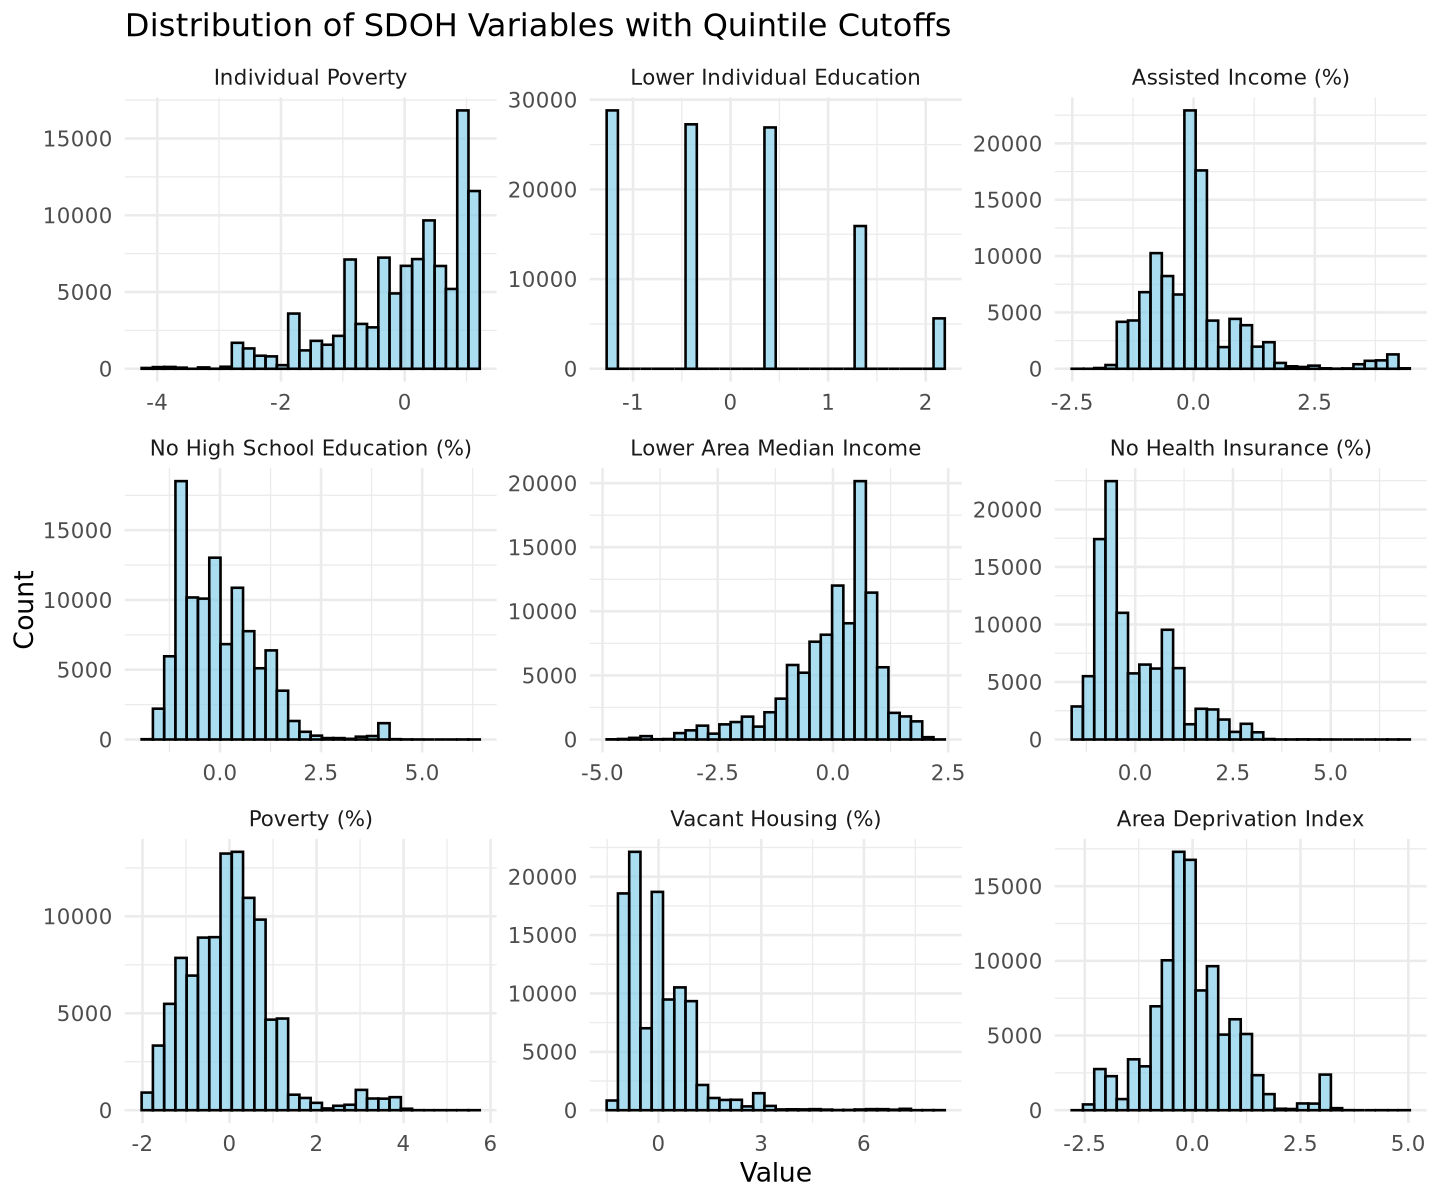

In [5]:
options(
    repr.plot.width  = 12,
    repr.plot.height = 10
  )

# Z-score normalize the domain columns
merged_z <- merged_data %>%
  mutate(across(all_of(sdoh_var), ~ (. - mean(., na.rm = TRUE)) / sd(., na.rm = TRUE)))

# --- Reshape to long format ---
long_data <- merged_z %>%
  select(all_of(sdoh_var)) %>%
  pivot_longer(cols = everything(), names_to = "domain", values_to = "value")

#Clean up
long_data$domain <- social_name_mapping_distributions[long_data$domain]

#Order
sdoh_distribution_order <- c( "Individual Poverty", "Lower Individual Education",  "Assisted Income (%)",
  "No High School Education (%)", "Lower Area Median Income", "No Health Insurance (%)",
  "Poverty (%)", "Vacant Housing (%)", "Area Deprivation Index"
)

long_data <- long_data %>%
    mutate(
      domain       = factor(domain, levels = sdoh_distribution_order ))



# --- Faceted histogram plot ---
ggplot(long_data, aes(x = value)) +
  geom_histogram(bins = 30, fill = "skyblue", color = "black", alpha = 0.7) +
  facet_wrap(~ domain, scales = "free") +
  labs(x = "Value", y = "Count", title = "Distribution of SDOH Variables with Quintile Cutoffs") +
  theme_minimal(base_size = 16)



# Regressions

## Make functions

In [6]:
generate_genetic_formula <- function(disease) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

fit_whole_population <- function(formula, disease, data) {
  
  # Disease specific filters
  if (disease %in% c("CKD", "t1d")) data <- data %>% filter(SexGenderSGM == 0)
  if (disease == "BreastC")         data <- data %>% filter(SexGenderCis_female == 1)
  if (disease == "ProstateC")       data <- data %>% filter(SexGenderCis_male == 1)

  # Fit model on the full filtered population
  model <- glm(formula, data = data, family = binomial(link = "logit"))
  
  # Calculate predictions and AUC
  preds <- predict(model, type = "response")
  actuals <- model$y

  if (length(unique(actuals)) > 1) {
    roc_obj <- roc(actuals, preds, quiet = TRUE)
    auc <- as.numeric(roc_obj$auc)
    auc_ci <- ci.auc(roc_obj)
  } else {
    auc <- NA
    auc_ci <- c(NA, NA, NA)
  }
  
  # Extract model coefficients
  results <- tidy(model) %>%
    mutate(
      Disease = disease,
      AUC = auc,
      AUC_CI_Lower = auc_ci[1],
      AUC_CI_Upper = auc_ci[3],
      OR = exp(estimate),
      OR_Lower = exp(estimate - 1.96 * std.error),
      OR_Upper = exp(estimate + 1.96 * std.error)
    )

  return(results)
}


## Run

In [7]:
# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

### Step 1: Generate formulas and fit models for whole population
results_whole_pop <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_genetic_formula(disease)),  # Generate formula for each disease
    results_whole_pop = list(fit_whole_population(formula, disease, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(results_whole_pop) %>%
  unnest(results_whole_pop)

#Map names for display
results_whole_pop$Disease <- disease_name_mapping[results_whole_pop$Disease]

#Clean up results
results_whole_pop <- results_whole_pop[grep("adjusted_score", results_whole_pop$term), ] #Only interested in PRS term

results_whole_pop <- results_whole_pop %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order)
    ) %>%
    distinct()
results_whole_pop$term <- "PRS"


Warning message:
“There were 9 warnings in `mutate()`.
The first warning was:
ℹ In argument: `results_whole_pop = list(fit_whole_population(formula, disease,
  merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 8 remaining warnings.”


# Graph PRS Odds Ratios 

Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
Ignoring unknown labels:
• colour : "PRS"
`height` was translated to `width`.


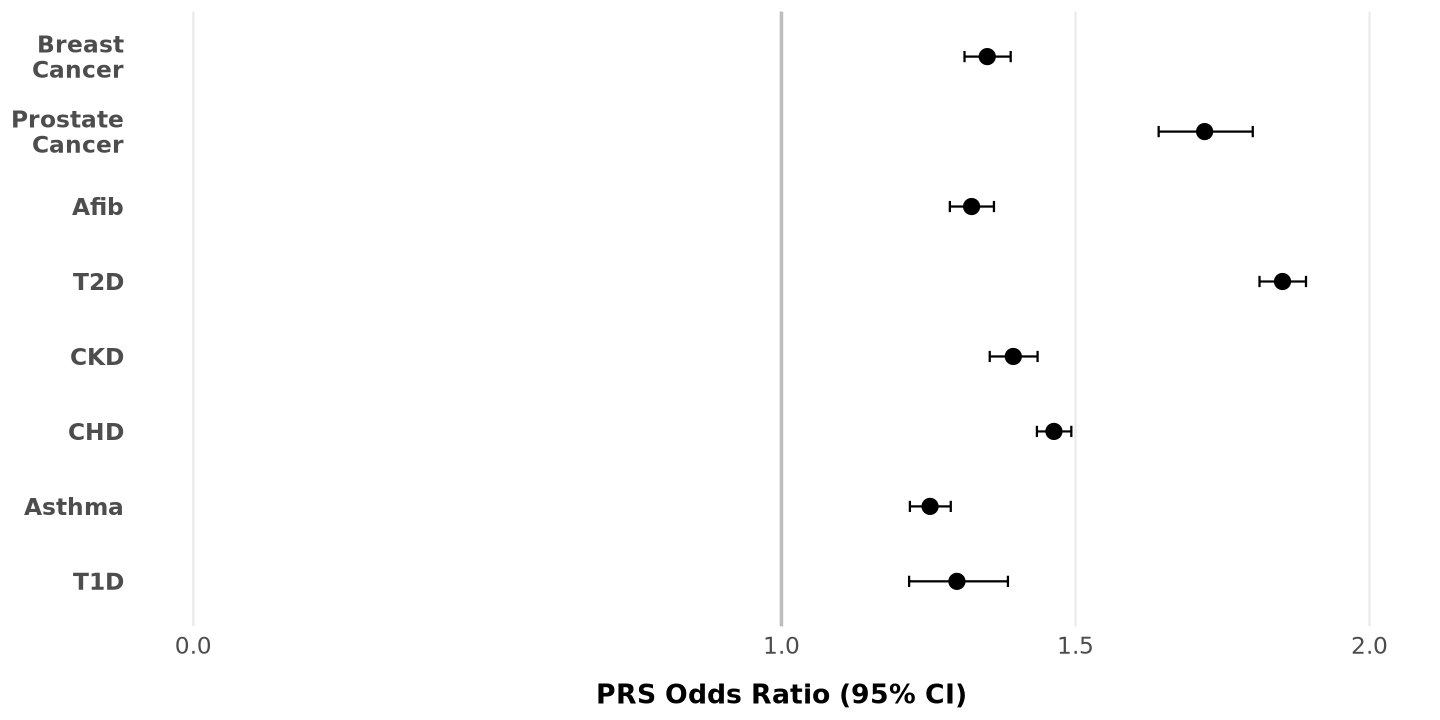

In [8]:
plot_sdoh_prs_forest_whole_pop <- function(
  df,
  width  = 12,
  height = 6,
  x_label = "PRS Odds Ratio (95% CI)"
) {

  df <- df %>%
    filter(term != "(Intercept)") %>%
    mutate(
      Disease = factor(Disease, levels = rev(disease_order))
    )

  p <- ggplot(
    df,
    aes(
      x = OR,
      y = Disease,
      group = term
    )
  ) +

    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper
      ),
      height = 0.15,
      position = position_dodge(width = 0.6)
    ) +

    geom_point(
      size = 4,
      position = position_dodge(width = 0.6)
    ) +

    geom_vline(
      xintercept = 1,
      color = "grey",
      linewidth = 1
    ) +

    scale_x_continuous(
      name = x_label,
      breaks = c(0, 1, 1.5, 2),
      limits = c(
        0,
        max(1, 2)
      )
    ) +

    labs(
      y = NULL,
      color = "PRS"
    ) +

    theme_minimal(base_size = 14) +

    theme(
      axis.text.x = element_text(size = 14),
      axis.text.y = element_text(
        size = 14,
        face = "bold"
      ),
      axis.title.x = element_text(
        size = 16,
        face = "bold",
        margin = margin(t = 15)
      ),
      panel.grid.minor = element_blank(),
      panel.grid.major.y = element_blank(),
      legend.position = "bottom",
      legend.title = element_text(face = "bold")
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

plot_sdoh_prs_forest_whole_pop(results_whole_pop)

# PRS and SDoH Associations

In [9]:
generate_formulas <- function(disease, domain) {
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  if (disease %in% c("CKD", "t1d")) sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  f <- as.formula(paste(disease, "~", paste(c(base, score, domain), collapse = " + ")))
  list(f)  # return a LIST
}

# accept either a formula OR a list of formulas
fit_and_extract <- function(formulas, disease, domain, data) {
  if (inherits(formulas, "formula")) formulas <- list(formulas)

  map_dfr(formulas, ~{
    filtered_data <- data
    if (disease %in% c("CKD", "t1d")) filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    if (disease == "BreastC")         filtered_data <- filtered_data %>% filter(SexGenderCis_female == 1)
    if (disease == "ProstateC")       filtered_data <- filtered_data %>% filter(SexGenderCis_male == 1)

    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    model <- suppressWarnings(glm(.x, data = filtered_data, family = binomial(link = "logit")))

    preds   <- predict(model, type = "response")
    actuals <- model$y

     # Case/control sample sizes used in model
      n_cases <- sum(actuals == 1, na.rm = TRUE)
      n_controls <- sum(actuals == 0, na.rm = TRUE)
      n_total <- length(actuals)
      
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)
      auc_val <- as.numeric(roc_obj$auc)
      auc_ci  <- as.numeric(ci.auc(roc_obj))
    } else {
      auc_val <- NA_real_; auc_ci <- c(NA_real_, NA_real_, NA_real_)
    }

    tidy_model <- tidy(model)

    if (nrow(tidy_model) > 0) {
      tidy_model <- tidy_model %>%
        mutate(
          estimate_CI_lower = estimate - 1.96 * std.error,
          estimate_CI_upper = estimate + 1.96 * std.error
        )
    } else {
      # Create empty columns if tidy_model has no rows
      tidy_model <- tibble(
        term = character(0),
        estimate = numeric(0),
        std.error = numeric(0),
        statistic = numeric(0),
        p.value = numeric(0),
        estimate_CI_lower = numeric(0),
        estimate_CI_upper = numeric(0)
      )
    }

    tidy_model %>%
      mutate(
        Disease       = disease,
        Domain        = domain,
          OR = exp(estimate),
         OR_Lower = exp(estimate - 1.96 * std.error),
         OR_Upper = exp(estimate + 1.96 * std.error),
        Model_Formula = paste(deparse(.x), collapse = " "),
          n_cases = n_cases,
          n_controls = n_controls,
          n_total = n_total,
        AUC           = auc_val,
        AUC_CI_Lower  = auc_ci[1],
        AUC_CI_Upper  = auc_ci[3]
      )
  })
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = sdoh_var
)

#Get results
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, merged_z))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, 
         n_cases, n_controls, n_total,
         estimate, std.error, statistic, p.value, 
         OR, OR_Lower, OR_Upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)
results_sdoh <- results |>
  filter(term %in% sdoh_var) |>
    select(Disease, term, p.value, OR, OR_Lower, OR_Upper)

results_sdoh$term <- social_name_mapping[results_sdoh$term]

results_prs <- results |>  filter(
    grepl("adjusted_score", term)
  ) |>
  group_by(Disease, is_adjusted = grepl("adjusted_score", term)) |>
  slice_min(
    abs(OR - median(OR, na.rm = TRUE)),
    n = 1,
    with_ties = FALSE
  ) |>
  ungroup() |>
  select(Disease, term, p.value, OR, OR_Lower, OR_Upper)
results_prs$term <- "PRS"

results_filtered <- rbind(results_prs, results_sdoh)
results_filtered$Disease <- disease_name_mapping[results_filtered$Disease]

results_filtered <- results_filtered |> 
  mutate(
    bonf_sig = p.value < alpha_bonf,
    sig = case_when(
      p.value < alpha_bonf ~ "bonf",
      p.value < 0.05 ~ "sig",
       TRUE ~ "not_sig"
    )
  )

# PRS and SDoH Associations adj PCs

In [10]:
generate_formulas <- function(disease, domain) {
  covariates <- c("age", "age2", "record_depth", "visit_frequency", paste0("PC_", 1:16))
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  if (disease %in% c("CKD", "t1d")) sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  f <- as.formula(paste(disease, "~", paste(c(base, score, domain), collapse = " + ")))
  list(f)  # return a LIST
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = sdoh_var
)

#Get results
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, merged_z))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, 
         n_cases, n_controls, n_total,
         estimate, std.error, statistic, p.value, 
         OR, OR_Lower, OR_Upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)
results_sdoh <- results |>
  filter(term %in% sdoh_var) |>
    select(Disease, term, p.value, OR, OR_Lower, OR_Upper)

results_sdoh <- results |>
  filter(term %in% sdoh_var) |>
    select(Disease, term, p.value, OR, OR_Lower, OR_Upper)

results_sdoh$term <- social_name_mapping[results_sdoh$term]

results_prs <- results |>  filter(
    grepl("adjusted_score", term)
  ) |>
  group_by(Disease, is_adjusted = grepl("adjusted_score", term)) |>
  slice_min(
    abs(OR - median(OR, na.rm = TRUE)),
    n = 1,
    with_ties = FALSE
  ) |>
  ungroup() |>
  select(Disease, term, p.value, OR, OR_Lower, OR_Upper)
results_prs$term <- "PRS"

results_filtered_adj_PCs <- rbind(results_prs, results_sdoh)
results_filtered_adj_PCs$Disease <- disease_name_mapping[results_filtered_adj_PCs$Disease]

results_filtered_adj_PCs <- results_filtered_adj_PCs |> 
  mutate(
    bonf_sig = p.value < alpha_bonf,
    sig = case_when(
      p.value < alpha_bonf ~ "bonf",
      p.value < 0.05 ~ "sig",
       TRUE ~ "not_sig"
    )
  )

# Plot PRS and SDoH var

In [11]:
results_filtered$adjustment <- "No"
results_filtered_adj_PCs$adjustment <- "Yes"

results_filtered_all <- rbind(results_filtered, results_filtered_adj_PCs)


`height` was translated to `width`.
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's alpha values.”


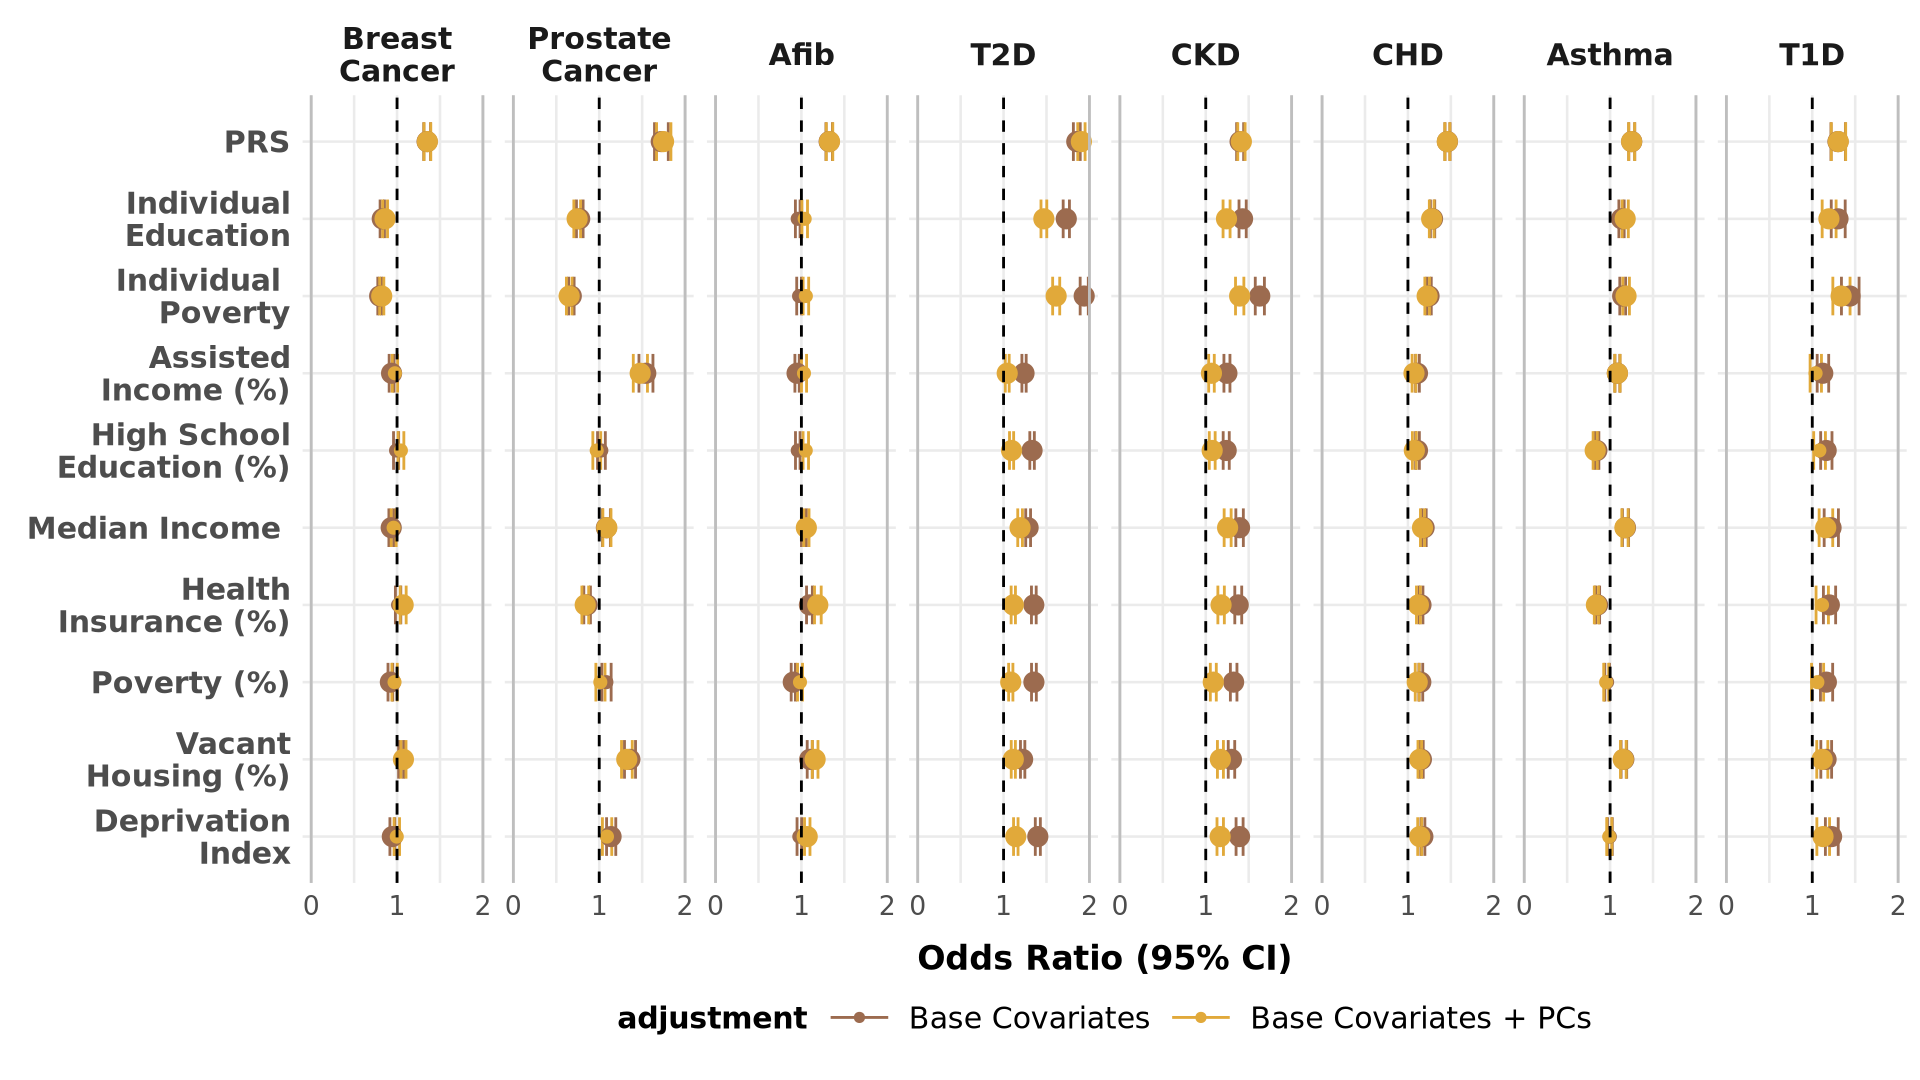

In [15]:
plot_prs_sdoh_forest <- function(
  df,
  width = 16,
  height = 9,
  x_label = "Odds Ratio (95% CI)"
) {

  # Make PRS/SDoH ordering consistent
  df <- df |>
    mutate(
      term = factor(term, levels = rev(unique(term))),
    Disease = factor(Disease, levels = disease_order),
    term = factor(term, levels = rev(c("PRS", sdoh_order))),

    )

  p <- ggplot(
    df,
    aes(
      x = OR,
      y = term,
        color = adjustment
    )
  ) +

    # 95% CI
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper
      ),
      height = 0.5,
      linewidth = 0.8
    ) +

    # OR
    geom_point(
      aes(
        alpha = sig,
        size  = bonf_sig
      )
    ) +

    scale_color_manual(
      values = c(Yes = "#E1A93A", No = "#9C6B4F"), 
      labels = c(
        Yes = "Base Covariates + PCs",
        No = "Base Covariates"
      )
    ) +

    # Null OR
    geom_vline(
      xintercept = 1,
      color = "black",
      linewidth = 0.8,
        linetype =2
    ) +

    # Disease across columns
    facet_grid(
      cols = vars(Disease)
    ) +

    scale_size_manual(
      values = c(`FALSE` = 3, `TRUE` = 5),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

        # Separate diseases
    geom_vline(
      xintercept = 0,
      color = "grey",
      linewidth = 0.8
    ) +

    geom_vline(
      xintercept = 2,
      color = "grey",
      linewidth = 0.8
    ) +

    
    scale_x_continuous(
      name = x_label,
      breaks = c(0, 0.5, 1, 1.5, 2),
        labels = c("0", "", "1", "", "2"),
      limits = c(
        min(0, min(df$OR_Lower, na.rm = TRUE)),
        max(2, max(df$OR_Upper, na.rm = TRUE))
      )
    ) +

    labs(
      y = NULL
    ) +

     theme_minimal(base_size = 16) +
    theme(
      axis.text.x        = element_text(size = 16, margin = margin(t = 4), angle = 0),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 20, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_text(size = 18, face = "bold"),
      strip.text.y.left  = element_text(size = 18, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 18, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 18),
      legend.title       = element_text(size = 18, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) 

  options(
    repr.plot.width = width,
    repr.plot.height = height
  )

  p
}

p <- plot_prs_sdoh_forest(results_filtered_all)

print(p)

`height` was translated to `width`.


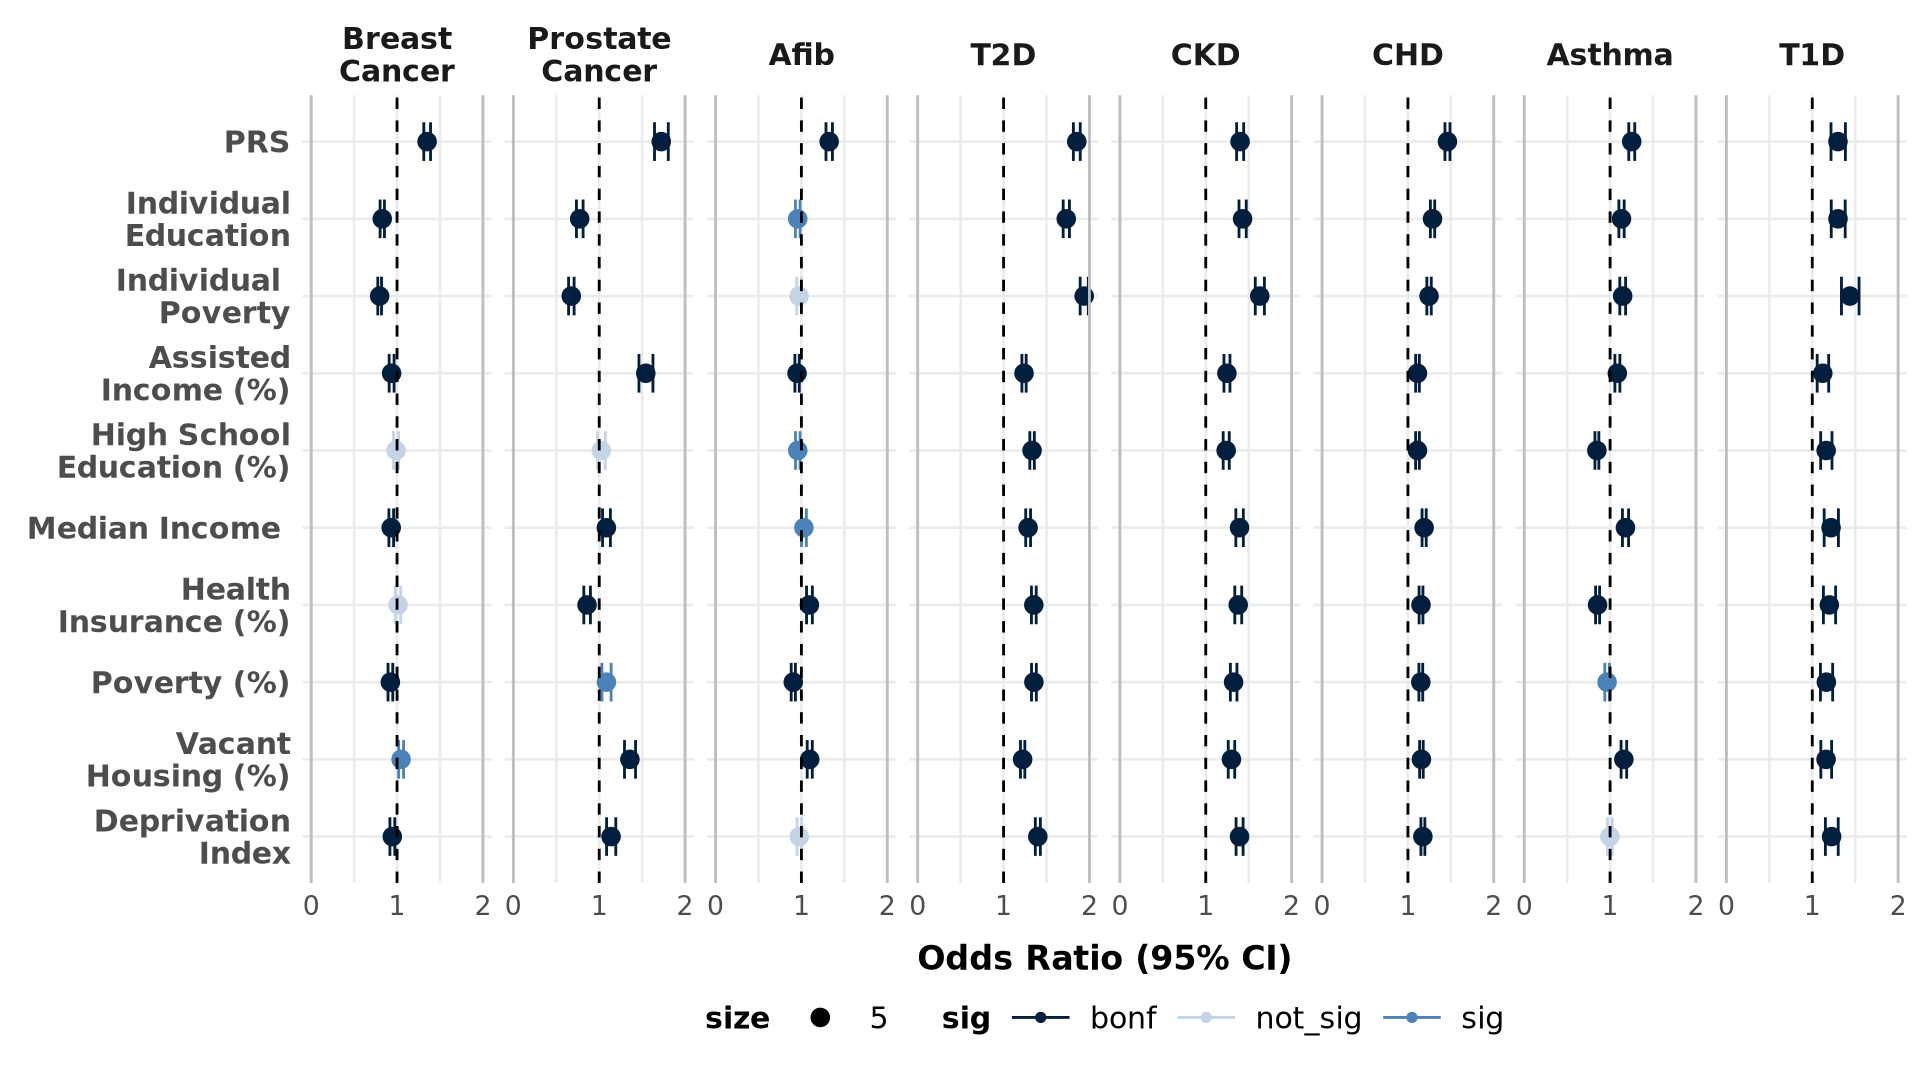

In [16]:
plot_prs_sdoh_forest <- function(
  df,
  width = 16,
  height = 9,
  x_label = "Odds Ratio (95% CI)"
) {

  # Make PRS/SDoH ordering consistent
  df <- df |>
    mutate(
      term = factor(term, levels = rev(unique(term))),
    Disease = factor(Disease, levels = disease_order),
    term = factor(term, levels = rev(c("PRS", sdoh_order))),
    )

  p <- ggplot(
    df,
    aes(
      x = OR,
      y = term,
        color = sig
    )
  ) +

    geom_point(
      aes(
        size  = 5
      )
    ) +

    # 95% CI
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper
      ),
      height = 0.5,
      linewidth = 0.8
    ) +
    
    # Null OR
    geom_vline(
      xintercept = 1,
      color = "black",
      linewidth = 0.8,
        linetype = 2
    ) +

    # Separate diseases
    geom_vline(
      xintercept = 0,
      color = "grey",
      linewidth = 0.8
    ) +

    geom_vline(
      xintercept = 2,
      color = "grey",
      linewidth = 0.8
    ) +

    scale_color_manual(
      values = c( `bonf` = "#001F3F",
                 `sig` = "#4B83B9",
                 `not_sig` = "#C4D4E6"
                )
    ) +

    # Disease across columns
    facet_grid(
      cols = vars(Disease)
    ) +
    
    scale_x_continuous(
      name = x_label,
      breaks = c(0, .5, 1, 1.5, 2),
        labels = c(0, "", "1", "", "2"),
      limits = c(
        min(0, min(df$OR_Lower, na.rm = TRUE)),
        max(2, max(df$OR_Upper, na.rm = TRUE))
      )
    ) +

    labs(
      y = NULL
    ) +

     theme_minimal(base_size = 16) +
    theme(
      axis.text.x        = element_text(size = 16, margin = margin(t = 4), angle = 0),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 20, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_text(size = 18, face = "bold"),
      strip.text.y.left  = element_text(size = 18, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 18, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 18),
      legend.title       = element_text(size = 18, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) 

  options(
    repr.plot.width = width,
    repr.plot.height = height
  )

  p
}

p <- plot_prs_sdoh_forest(results_filtered)

print(p)

# A tibble: 8 × 3
  Disease            n_cases y              
  <fct>                <int> <chr>          
1 "Breast\nCancer"      5220 Number of cases
2 "Prostate\nCancer"    3494 Number of cases
3 "Afib"                8222 Number of cases
4 "T2D"                17747 Number of cases
5 "CKD"                 9214 Number of cases
6 "CHD"                14863 Number of cases
7 "Asthma"             12315 Number of cases
8 "T1D"                 1079 Number of cases


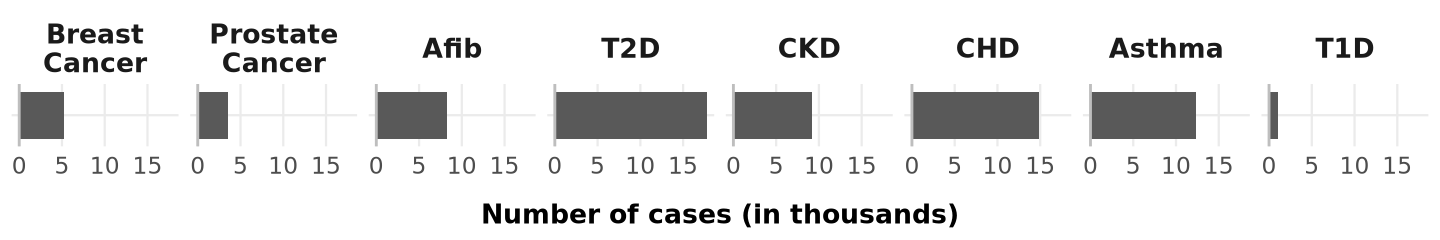

In [19]:
plot_sdoh_prs_case_bar <- function(
  df,
  width  = 12,
  height = 2,
  x_label = "Case Sample Size"
) {

    # Make ordering consistent
    df$Disease <- disease_name_mapping[df$Disease]

  df <- df |>
    mutate(
    Disease = factor(Disease, levels = disease_order)
    )

 df <- df %>%
  group_by(Disease) %>%
  summarise(
    n_cases = first(n_cases),
    .groups = "drop"
  )
   df$y <- "Number of cases"

  print(df)

  p <- ggplot(
    df,
    aes(
      x = n_cases,
       y = y
     
    )
  ) +

    # Horizontal bars
    geom_col() +

    # Keep diseases as columns
    facet_grid(
      cols = vars(Disease)
    ) +

        # Separate diseases
    geom_vline(
      xintercept = 0,
      color = "grey",
      linewidth = 0.8
    ) +

    scale_x_continuous(
  breaks = c(0, 5000, 10000, 15000),
  labels = c("0", "5", "10", "15"),
     name = "Number of cases (in thousands)"   
   ) +
    
    theme_minimal(base_size = 14) +
    theme(
      axis.text.x = element_text(
        size = 14,
        margin = margin(t = 4)
      ),
      panel.grid.minor = element_blank(),
      axis.title.y = element_blank(),
      axis.title.x = element_text(
        size = 16,
        face = "bold",
        margin = margin(t = 15)
      ),
      axis.text.y = element_blank(),
      strip.text.x = element_text(
        size = 16,
        face = "bold"
      ),
      legend.position = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text = element_text(size = 16),
      legend.title = element_text(
        size = 16,
        face = "bold"
      ),
      legend.key.size = unit(3, "lines")
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

p_bar <- plot_sdoh_prs_case_bar(results)
print(p_bar)

In [15]:
write_excel_csv(results_filtered_all, file.path(output_dir, "OR_main_effects.csv"))


# A tibble: 8 × 2
  Disease            n_controls
  <fct>                   <dbl>
1 "Breast\nCancer"       0.0905
2 "Prostate\nCancer"     0.578 
3 "Afib"                 0.465 
4 "T2D"                  0.501 
5 "CKD"                  0.297 
6 "CHD"                  0.175 
7 "Asthma"               0.684 
8 "T1D"                  0.0311


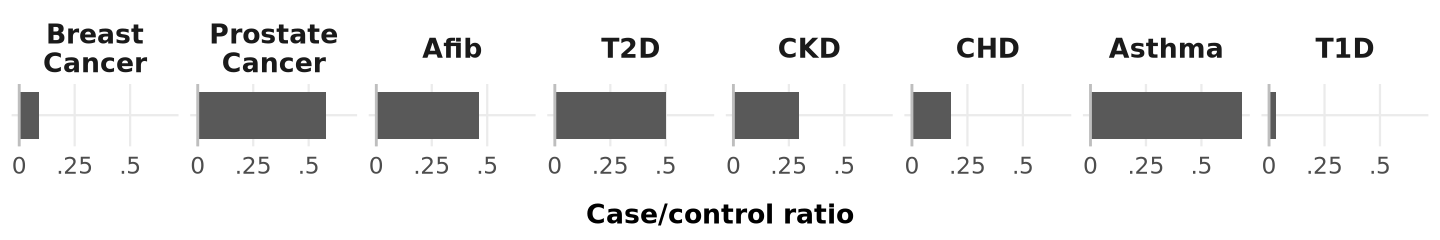

In [20]:
plot_sdoh_prs_control_bar <- function(
  df,
  width  = 12,
  height = 2,
  x_label = "Control Sample Size"
) {

    # Make ordering consistent
    df$Disease <- disease_name_mapping[df$Disease]

  df <- df |>
    mutate(
    Disease = factor(Disease, levels = disease_order)
    )

 df <- df %>%
  group_by(Disease) %>%
  summarise(
    n_controls = first(n_cases/n_controls),
    .groups = "drop"
  )

    print(df) 
    
   df$y <- "Number of controls"

  p <- ggplot(
    df,
    aes(
      x = n_controls,
       y = y
     
    )
  ) +

    # Horizontal bars
    geom_col() +

    # Keep diseases as columns
    facet_grid(
      cols = vars(Disease)
    ) +

        # Separate diseases
    geom_vline(
      xintercept = 0,
      color = "grey",
      linewidth = 0.8
    ) +

    scale_x_continuous(
  breaks = c(0, 0.25, 0.5),
  labels = c("0", ".25", ".5"),
     name = "Case/control ratio"   
   ) +
    
    theme_minimal(base_size = 14) +
    theme(
      axis.text.x = element_text(
        size = 14,
        margin = margin(t = 4)
      ),
      panel.grid.minor = element_blank(),
      axis.title.y = element_blank(),
      axis.title.x = element_text(
        size = 16,
        face = "bold",
        margin = margin(t = 15)
      ),
      axis.text.y = element_blank(),
      strip.text.x = element_text(
        size = 16,
        face = "bold"
      ),
      legend.position = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text = element_text(size = 16),
      legend.title = element_text(
        size = 16,
        face = "bold"
      ),
      legend.key.size = unit(3, "lines")
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

p_bar <- plot_sdoh_prs_control_bar(results)
print(p_bar)